# RQ4b-3 — Adversarial-debiasing RealMLP results

This notebook is a presentation-only consumer of the accepted RQ4b-3 evaluation packages:

| Package | Role | Run ID |
|---|---|---|
| Gate C aggregation | Validation-only evaluation of the nine development units and the locked lambda selection | `rq4b3_gatec_20261024_01` |
| Test evaluation + package validation | Saved-model Test evaluation of the nine user-selected arms, then a no-inference recomputation check | `rq4b3_test_20261024_01` |

It reads only the published Gate C stage outputs, the Test run manifest, the `test_evaluation` table outputs and receipts, and the `package_validation` receipt and report. It does not read raw data, split partitions, model or preprocessor files, or bootstrap indices. It does not parse prediction files; those are hashed only for receipt integrity. It does not fit, predict, bootstrap or recompute any metric or interval. Every number comes from the stored artifacts. Tables only round values for display. The few in-notebook descriptive summaries of stored Validation values are labelled and asserted against the stored Gate C values.

All results use the project orientation `Approved = 1`. They describe the behaviour of the RealMLP approval model with an adversarial debiasing term for the documented HMDA approval cohort. They are not evidence of legal discrimination, causal effects, creditworthiness or default risk.

**Interpretation ownership.** Machine code assigns no research pass/fail, mitigation-effectiveness, support or recommendation label. The research interpretation section at the end is reserved for the user.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "config/dataset_b/rq4b_adversarial.yaml").exists())
CONFIG_PATH = project_root / "config/dataset_b/rq4b_adversarial.yaml"
GATE_C_RUN = "rq4b3_gatec_20261024_01"
TEST_RUN = "rq4b3_test_20261024_01"
GATE_C_DIR = project_root / "artifacts/dataset_b/rq4/rq4b/gate_c_aggregation" / GATE_C_RUN
TEST_DIR = project_root / "artifacts/dataset_b/rq4/rq4b/test_evaluation" / TEST_RUN
TEST_STAGE = TEST_DIR / "stages/test_evaluation"
PACKAGE_STAGE = TEST_DIR / "stages/package_validation"
GATE_C_STAGE = GATE_C_DIR / "stages/gate_c_aggregation"
REPLICATED_LAMBDAS = [0.0, 0.01]
SCREENING_LAMBDAS = [0.03, 0.1, 0.3]
SEEDS = [42, 43, 44]
G3 = ["White", "Black or African American", "Asian"]
G6 = G3 + ["American Indian or Alaska Native", "2 or more minority races", "Joint"]
ROLE_LABEL = {"gate_c_selected_control": "control (Gate C selection)", "user_requested_comparator": "replicated comparator", "user_requested_screening": "screening (seed 42 only)"}
ATOL_POINT = 1.0e-12  # locked point-metric tolerance (split_and_evaluation.md section 7)


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def read_table(name):
    frame = pd.read_csv(TEST_STAGE / name, float_precision="round_trip")
    for column in ("adversary_lambda", "comparator_lambda", "control_lambda"):
        if column in frame:
            frame[column] = frame[column].round(6)  # stored as %.17g floats; display/matching key only
    return frame


def lam_label(value):
    return f"{value:g}"


config = yaml.safe_load(CONFIG_PATH.read_text(encoding="utf-8"))
test_contract = config["test_evaluation"]
print("Notebook kernel:", sys.executable, "| Python", platform.python_version(), "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
print("Gate C package ->", GATE_C_DIR.relative_to(project_root).as_posix())
print("Test package   ->", TEST_DIR.relative_to(project_root).as_posix())

Notebook kernel: C:\Users\Dan\anaconda3\python.exe | Python 3.13.9 | pandas 2.3.3 | matplotlib 3.10.6
Gate C package -> artifacts/dataset_b/rq4/rq4b/gate_c_aggregation/rq4b3_gatec_20261024_01
Test package   -> artifacts/dataset_b/rq4/rq4b/test_evaluation/rq4b3_test_20261024_01


## 1. Package integrity

Each published stage is checked as follows. The files present must equal the outputs recorded in the stage receipt, and every file's SHA-256 must match the receipt. The three Gate C files must also match the digests locked in `rq4b_adversarial.yaml`. Prediction CSVs are hashed only and are never parsed.

In [2]:
def stage_integrity(stage_dir, label):
    receipt = read_json(stage_dir / "receipt.json")
    present = {path.name for path in stage_dir.iterdir()} - {"receipt.json"}
    rows = [{"stage": label, "file": name, "in_receipt": name in receipt["outputs"], "sha256_matches_receipt": name in receipt["outputs"] and sha256(stage_dir / name) == receipt["outputs"][name]} for name in sorted(present | set(receipt["outputs"]))]
    return receipt, rows


gate_c_receipt, gate_rows = stage_integrity(GATE_C_STAGE, "gate_c_aggregation")
test_receipt, test_rows = stage_integrity(TEST_STAGE, "test_evaluation")
package_receipt, package_rows = stage_integrity(PACKAGE_STAGE, "package_validation")
integrity = pd.DataFrame(gate_rows + test_rows + package_rows)
display(integrity.groupby("stage").agg(files=("file", "count"), all_in_receipt=("in_receipt", "all"), all_sha256_match=("sha256_matches_receipt", "all")))
assert integrity["in_receipt"].all() and integrity["sha256_matches_receipt"].all(), "A stage file differs from its receipt."

lineage = test_contract["lineage"]
test_manifest = read_json(TEST_DIR / "run_manifest.json")
locked = pd.DataFrame([
    {"artifact": "Gate C run_manifest.json", "sha256": sha256(GATE_C_DIR / "run_manifest.json"), "locked": lineage["gate_c_manifest_sha256"], "lock_source": "rq4b_adversarial.yaml"},
    {"artifact": "Gate C receipt.json", "sha256": sha256(GATE_C_STAGE / "receipt.json"), "locked": lineage["gate_c_receipt_sha256"], "lock_source": "rq4b_adversarial.yaml"},
    {"artifact": "Gate C gate_c_selection.json", "sha256": sha256(GATE_C_STAGE / "gate_c_selection.json"), "locked": gate_c_receipt["outputs"]["gate_c_selection.json"], "lock_source": "pinned Gate C receipt"},
])
locked["matches"] = locked["sha256"] == locked["locked"]
display(locked)
assert locked["matches"].all(), "A Gate C artifact differs from its locked digest."
assert test_manifest["gate_c_pins"] == {"manifest": locked.loc[0, "sha256"], "receipt": locked.loc[1, "sha256"], "selection": locked.loc[2, "sha256"]}, "Test manifest Gate C pins differ."

bootstrap_lock = lineage["locked_test_bootstrap_indices"]
recorded_bootstrap = test_manifest["bootstrap_index_pin"]
assert recorded_bootstrap["sha256"] == bootstrap_lock["sha256"] == config["uncertainty"]["within_seed"]["indices_sha256"], "Bootstrap index pin differs."
assert recorded_bootstrap["array"] == bootstrap_lock["array"] and recorded_bootstrap["replicates"] == bootstrap_lock["replicates"] == 1000
print("Bootstrap index pin (from Test manifest; the index file itself is not read):", recorded_bootstrap["sha256"], "| array", recorded_bootstrap["array"], "| replicates", recorded_bootstrap["replicates"])
assert package_receipt["inputs"] == {"test_evaluation": sha256(TEST_STAGE / "receipt.json")}, "Package receipt does not pin the current Test receipt."
print("Test run_manifest.json sha256:", sha256(TEST_DIR / "run_manifest.json"))
print("Test receipt.json sha256:     ", sha256(TEST_STAGE / "receipt.json"))
print("Package receipt.json sha256:  ", sha256(PACKAGE_STAGE / "receipt.json"))

,files,all_in_receipt,all_sha256_match
stage,,,
gate_c_aggregation,1,True,True
package_validation,1,True,True
test_evaluation,18,True,True


,artifact,sha256,locked,lock_source,matches
0,Gate C run_manifest.json,5d072d7ff094817b8a281d2ea5b6527682678f97d09fa5...,5d072d7ff094817b8a281d2ea5b6527682678f97d09fa5...,rq4b_adversarial.yaml,True
1,Gate C receipt.json,14f602bb0ef59d7cbfb22e8b5fbdaf6604e5a90c295370...,14f602bb0ef59d7cbfb22e8b5fbdaf6604e5a90c295370...,rq4b_adversarial.yaml,True
2,Gate C gate_c_selection.json,76af4d077ea9febbb8865008c6d566923ddb66e88f5026...,76af4d077ea9febbb8865008c6d566923ddb66e88f5026...,pinned Gate C receipt,True


Bootstrap index pin (from Test manifest; the index file itself is not read): 2ee377b6fbae8a3a6453a7d8f2f4a0a3f1ce61374f1258ef882589b84230fee1 | array indices | replicates 1000
Test run_manifest.json sha256: d05fc2980986452428b5fc656aaba89c8bad698923cab7da67f5ff241e7595a4
Test receipt.json sha256:      2f7c1ae8b31d8df82b9342182cb40fb9b3c18aa783a31ff53eeeaf54e64632c4
Package receipt.json sha256:   d20fa9b13cd4f9b9e5e52e4c387f49a63791f4c95af3fa9903caecdbf1e5800a


## 2. Execution status and fit accounting

Execution status and fit accounting are operational facts. They are separate from metric values and from any research interpretation.

In [3]:
execution_status = read_json(TEST_STAGE / "execution_status.json")
package_report = read_json(PACKAGE_STAGE / "package_report.json")
status_rows = []
for label, receipt in (("gate_c_aggregation", gate_c_receipt), ("test_evaluation", test_receipt), ("package_validation", package_receipt)):
    counts = receipt["counts"]
    status_rows.append({
        "stage": label, "run_id": receipt["run_id"], "receipt_status": receipt["status"], "mode": receipt["mode"],
        "local_cv_fits": counts["cv_fold_fits"], "local_refits": counts["refit_fits"], "local_probe_fits": counts["probe_fits"],
        "saved_predictions": len(counts["predictions"]),
        "source_cv_fits": counts["source_fit_accounting"]["cv_fold_fits"], "source_refits": counts["source_fit_accounting"]["refit_fits"],
        "started_utc": receipt["started_utc"], "finished_utc": receipt["finished_utc"],
    })
display(pd.DataFrame(status_rows))
display(pd.Series(execution_status, name="test execution_status.json").to_frame())
display(pd.Series({key: json.dumps(value) if isinstance(value, (dict, list)) else value for key, value in package_report.items()}, name="package_report.json").to_frame())

,stage,run_id,receipt_status,mode,local_cv_fits,local_refits,local_probe_fits,saved_predictions,source_cv_fits,source_refits,started_utc,finished_utc
0,gate_c_aggregation,rq4b3_gatec_20261024_01,PASS,evaluation_aggregation,0,0,0,0,45,9,2026-10-24T03:36:18.106345+00:00,2026-10-24T03:36:18.131605+00:00
1,test_evaluation,rq4b3_test_20261024_01,PASS,cross_run_test_evaluation,0,0,0,9,45,9,2026-10-24T09:00:10.799281+00:00,2026-10-24T09:00:13.348605+00:00
2,package_validation,rq4b3_test_20261024_01,PASS,cross_run_test_evaluation,0,0,0,0,45,9,2026-10-24T09:33:26.358242+00:00,2026-10-24T09:33:26.363359+00:00


,test execution_status.json
cv_fit_count,0
execution_status,completed
fit_count,0
inference_count,9
reason_codes,[none]
refit_count,0
test_rows,43996


,package_report.json
execution_status,completed
inference_performed,False
local_fit_counts,"{""cv_fold_fits"": 0, ""refit_fits"": 0}"
recomputed_from_saved_predictions,True
source_fit_accounting,"{""cv_fold_fits"": 45, ""refit_fits"": 9}"
verified_outputs,"[""arm_metrics.csv"", ""group_metrics.csv"", ""matc..."


## 3. Evaluation arms and lineage

The Test roster is exactly the nine saved development artifacts selected by the user. Lambda 0 is the stored Gate C selection, lambda 0.01 is the replicated comparator, and lambdas 0.03, 0.1 and 0.3 are seed-42 screening arms. Each arm uses its locked Validation threshold. There is no Test recalibration. The receipt hashes trace each arm to its source development and development-validation stages.

In [4]:
arms_manifest = pd.DataFrame(test_manifest["evaluation_arms"])
arms_manifest["adversary_lambda"] = arms_manifest["adversary_lambda"].round(6)
arms_manifest["role"] = arms_manifest["role"].map(ROLE_LABEL)
display(arms_manifest[["adversary_lambda", "seed", "role", "provenance", "run_id", "fit_key", "validation_key", "threshold", "fit_receipt_sha256", "validation_receipt_sha256", "estimator_sha256"]])

prediction_records = pd.DataFrame([{"file": name, **record} for name, record in test_receipt["counts"]["predictions"].items()])
display(prediction_records)
assert len(prediction_records) == 9 and (prediction_records["rows"] == 43996).all() and prediction_records["record_id_sha256"].nunique() == 1
assert sorted(zip(arms_manifest["adversary_lambda"], arms_manifest["seed"])) == sorted((round(arm["adversary_lambda"], 6), seed) for arm in test_contract["evaluation_arms"] for seed in arm["seeds"]), "Test arm roster differs from the locked contract."
display(pd.DataFrame([{"source_run_id": run_id, "manifest_sha256": pin["manifest_sha256"], "pinned_receipts": len(pin["evaluated_arm_receipt_sha256"])} for run_id, pin in test_manifest["source_pins"].items()]))

,adversary_lambda,seed,role,provenance,run_id,fit_key,validation_key,threshold,fit_receipt_sha256,validation_receipt_sha256,estimator_sha256
0,0.00,42,control (Gate C selection),gate_c_selected_lambda,rq4b3_adv_20261019_02,dev_l0_s42,devval_l0_s42,0.763,0734ace391cee86112039640a5b6cc6c7c63a98e0da63c...,99f6d38f9cb05a095422f8ec4a0e4b612593e09f207ffe...,d4dcee06805d5328890fe806db84635b79569b413a17f4...
1,0.00,43,control (Gate C selection),gate_c_selected_lambda,rq4b3_adv_20261021_01,dev_l0_s43,devval_l0_s43,0.766,3525c6605e5be3f4d59472fa3f538c7c3daa94e48df742...,b34dd1b9e0a322a35a20748361e34517de666f8080b1f3...,1712479fc2ff31fd7ae4e2212d930a786a7420f1fbf1c5...
2,0.00,44,control (Gate C selection),gate_c_selected_lambda,rq4b3_adv_20261022_01,dev_l0_s44,devval_l0_s44,0.753,5f5bf597283ffea13b05d42c147371b5bae92349cf0250...,82e34c7f7ade0926ac9841b6b0f32427248fec01cbba8f...,2a3bfbcad38fac9a323b07aebc5882842e8f6275fe1b90...
3,0.01,42,replicated comparator,explicit_user_test_request,rq4b3_adv_20261019_02,dev_l0p01_s42,devval_l0p01_s42,0.750,2fbf721f352fef151c00e512e288223411d04b48f84a19...,90da727f27b88e42626a9719bd9f64abae8bc0895c12d3...,51f74e5b6ca344e25d204cb1616c2d87e172d2f4e15c77...
4,0.01,43,replicated comparator,explicit_user_test_request,rq4b3_adv_20261021_01,dev_l0p01_s43,devval_l0p01_s43,0.754,cb3cd1bf6c75825bd7d44716799b709f68b4fa4ea3a919...,043e4fc03fa0e743dabce9d87be8deaac46658ca33aab1...,344cb1cf6bd5ef7b79e2b625c777268081239bb9d4def4...
5,0.01,44,replicated comparator,explicit_user_test_request,rq4b3_adv_20261022_01,dev_l0p01_s44,devval_l0p01_s44,0.766,e3c39216e7c1e09322fada1c5be5c1dd087830cd493a32...,6053990156cfdd8a5fb5da41f70121faae631c421db670...,ebbaa9aa8dfb3ff1a27df12ef9a5599c5e147673cc6eb5...
6,0.03,42,screening (seed 42 only),explicit_user_test_request,rq4b3_adv_20261019_02,dev_l0p03_s42,devval_l0p03_s42,0.741,0fe741be9b855bd5ea013c720677cfd2359e6728604373...,e6e7c55bd4b3921c8b8bdda9cef1c6a270e404479a0e22...,c9bfc42756fc60621140bf367a9e073fadd72d8c7f4ad3...
7,0.10,42,screening (seed 42 only),explicit_user_test_request,rq4b3_adv_20261019_02,dev_l0p1_s42,devval_l0p1_s42,0.738,54a26511089fc82d5fbce445246c6205678900216faaba...,fed37b989d0e3ae900ac9ee4a3e988860e38730491938f...,745905aeb202dd58e03d0ba29a2e85602aed0662bec37f...
8,0.30,42,screening (seed 42 only),explicit_user_test_request,rq4b3_adv_20261019_02,dev_l0p3_s42,devval_l0p3_s42,0.836,98e9aaa0de00f4f10469b12f24867432ef4a597d86a245...,8ec1b31a442f8c3070a7f66cde94e78b0723559b0fcddd...,80c44f89a0db6814360f2102dc612fe8d9052277c95572...


,file,artifact,partition,record_id_sha256,rows
0,test_predictions_l0_s42.csv,rq4b3_adv_20261019_02:dev_l0_s42,test,47dc67224270038649e6319db44b7a6d79abcdfb0bb4cc...,43996
1,test_predictions_l0_s43.csv,rq4b3_adv_20261021_01:dev_l0_s43,test,47dc67224270038649e6319db44b7a6d79abcdfb0bb4cc...,43996
2,test_predictions_l0_s44.csv,rq4b3_adv_20261022_01:dev_l0_s44,test,47dc67224270038649e6319db44b7a6d79abcdfb0bb4cc...,43996
3,test_predictions_l0p01_s42.csv,rq4b3_adv_20261019_02:dev_l0p01_s42,test,47dc67224270038649e6319db44b7a6d79abcdfb0bb4cc...,43996
4,test_predictions_l0p01_s43.csv,rq4b3_adv_20261021_01:dev_l0p01_s43,test,47dc67224270038649e6319db44b7a6d79abcdfb0bb4cc...,43996
5,test_predictions_l0p01_s44.csv,rq4b3_adv_20261022_01:dev_l0p01_s44,test,47dc67224270038649e6319db44b7a6d79abcdfb0bb4cc...,43996
6,test_predictions_l0p03_s42.csv,rq4b3_adv_20261019_02:dev_l0p03_s42,test,47dc67224270038649e6319db44b7a6d79abcdfb0bb4cc...,43996
7,test_predictions_l0p1_s42.csv,rq4b3_adv_20261019_02:dev_l0p1_s42,test,47dc67224270038649e6319db44b7a6d79abcdfb0bb4cc...,43996
8,test_predictions_l0p3_s42.csv,rq4b3_adv_20261019_02:dev_l0p3_s42,test,47dc67224270038649e6319db44b7a6d79abcdfb0bb4cc...,43996


,source_run_id,manifest_sha256,pinned_receipts
0,rq4b3_adv_20261019_02,b84f5d018cd308a97d0918dd9ba336e8f449a8b5c16a7c...,10
1,rq4b3_adv_20261021_01,315bd175e1239230992c459fb937f8de9ca4f995527a5e...,4
2,rq4b3_adv_20261022_01,f6ebf429d4d0a5ec2b4abd08e247a6afa75b381da2da38...,4


## 4. Validation results by lambda and seed (Gate C)

These are the stored Gate C unit rows on the 43,995-row ordered Validation partition. The thresholds were calibrated on the same partition that the lambda selection used, so the Validation values are optimistic. Matched delta BA is the unit's BA minus its same-seed lambda-0 control. The stored selection policy considers only the replicated lambdas 0 and 0.01. EOD6 is an audit quantity only.

In [5]:
selection = read_json(GATE_C_STAGE / "gate_c_selection.json")
validation_units = pd.DataFrame(selection["units"])
validation_units["adversary_lambda"] = validation_units["adversary_lambda"].round(6)
validation_units = validation_units.sort_values(["adversary_lambda", "model_seed"]).reset_index(drop=True)
display(validation_units)

display(Markdown("**Stored Gate C selection record**"))
display(pd.Series({
    "status": selection["status"], "selected_lambda": selection["selected_lambda"], "lambda_zero_selected": selection["lambda_zero_selected"],
    "eod6_role": selection["eod6_role"], "screening_only_lambdas": selection["screening_only_lambdas"],
    "arbitrary_two_of_three_rule_used": selection["arbitrary_two_of_three_rule_used"], "limitation": selection["limitation"],
    "validation_rows": selection["validation_rows"], "validation_record_id_sha256": selection["validation_record_id_sha256"],
}, name="value").to_frame())
display(pd.DataFrame(selection["candidates"]))
display(Markdown("**Stored training-stability labels**"))
stability = pd.DataFrame(selection["training_stability"])
stability["adversary_lambda"] = stability["adversary_lambda"].round(6)
display(stability)

,adversary_lambda,balanced_accuracy,eod3,eod6_audit_only,matched_control_available,matched_delta_ba,model_seed,threshold
0,0.00,0.787739,0.102175,0.197714,True,0.000000,42,0.763
1,0.00,0.786845,0.100510,0.210972,True,0.000000,43,0.766
2,0.00,0.788131,0.096216,0.200634,True,0.000000,44,0.753
3,0.01,0.782444,0.097789,0.221579,True,-0.005294,42,0.750
4,0.01,0.783395,0.098545,0.214181,True,-0.003451,43,0.754
5,0.01,0.781844,0.111589,0.215367,True,-0.006287,44,0.766
6,0.03,0.759932,0.101761,0.241119,True,-0.027806,42,0.741
7,0.10,0.758913,0.097067,0.227511,True,-0.028825,42,0.738
8,0.30,0.759557,0.102478,0.201576,True,-0.028182,42,0.836


**Stored Gate C selection record**

,value
status,selected
selected_lambda,0.0
lambda_zero_selected,True
eod6_role,audit_only
screening_only_lambdas,"[0.03, 0.1, 0.3]"
arbitrary_two_of_three_rule_used,False
limitation,threshold calibration and lambda selection sha...
validation_rows,43995
validation_record_id_sha256,f5331875e449fc2f940de5a845483d5ea0830ae2b5a850...


,adversary_lambda,eligible,invalid_reason,mean_eod3,mean_matched_delta_ba
0,0.00,True,None,0.099633,0.000000
1,0.01,True,None,0.102641,-0.005011


**Stored training-stability labels**

,adversary_lambda,model_seed,status
0,0.00,42,not_observed_for_lambda_zero
1,0.01,42,training-unstable beyond selected epoch
2,0.03,42,training-unstable beyond selected epoch
3,0.10,42,training-unstable beyond selected epoch
4,0.30,42,training-unstable beyond selected epoch
5,0.00,43,not_observed_for_lambda_zero
6,0.01,43,training-unstable beyond selected epoch
7,0.00,44,not_observed_for_lambda_zero
8,0.01,44,training-unstable beyond selected epoch


### Validation seed variability (replicated lambdas)

The table below is an in-notebook descriptive summary (mean, sample SD with ddof=1, min, max, range) of the three stored Validation unit values per replicated lambda. As a check, the means of EOD3 and of matched delta BA are asserted to equal the stored Gate C candidate means within the locked point tolerance.

In [6]:
validation_summary_rows = []
for lam in REPLICATED_LAMBDAS:
    subset = validation_units[validation_units["adversary_lambda"] == lam]
    assert sorted(subset["model_seed"]) == SEEDS, f"Validation lambda {lam} lacks a seed."
    for quantity in ("balanced_accuracy", "eod3", "eod6_audit_only", "matched_delta_ba"):
        values = subset[quantity].to_numpy(dtype=float)
        validation_summary_rows.append({"adversary_lambda": lam, "quantity": quantity, "seed_count": len(values), "mean": values.mean(), "standard_deviation": values.std(ddof=1), "min": values.min(), "max": values.max(), "range": values.max() - values.min()})
validation_summary = pd.DataFrame(validation_summary_rows)
display(validation_summary)

summary_lookup = validation_summary.set_index(["adversary_lambda", "quantity"])["mean"]
for candidate in selection["candidates"]:
    lam = round(candidate["adversary_lambda"], 6)
    for quantity, stored in (("eod3", candidate["mean_eod3"]), ("matched_delta_ba", candidate["mean_matched_delta_ba"])):
        derived = summary_lookup.loc[(lam, quantity)]
        assert abs(derived - stored) <= ATOL_POINT, f"Derived Validation mean differs from stored Gate C value for {lam}/{quantity}."
print("Derived Validation means equal the stored Gate C candidate means (atol 1e-12).")

,adversary_lambda,quantity,seed_count,mean,standard_deviation,min,max,range
0,0.00,balanced_accuracy,3,0.787572,0.000659,0.786845,0.788131,0.001285
1,0.00,eod3,3,0.099633,0.003075,0.096216,0.102175,0.005959
2,0.00,eod6_audit_only,3,0.203107,0.006966,0.197714,0.210972,0.013258
3,0.00,matched_delta_ba,3,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.01,balanced_accuracy,3,0.782561,0.000782,0.781844,0.783395,0.001551
5,0.01,eod3,3,0.102641,0.007758,0.097789,0.111589,0.013800
6,0.01,eod6_audit_only,3,0.217042,0.003973,0.214181,0.221579,0.007398
7,0.01,matched_delta_ba,3,-0.005011,0.001439,-0.006287,-0.003451,0.002836


Derived Validation means equal the stored Gate C candidate means (atol 1e-12).


## 5. Test results by arm and seed

These are the stored full-Test point metrics for each arm on the 43,996-row ordered Test partition, with each arm's locked Validation threshold. EOD3 uses the fixed G3 roster. EOD6 uses the fixed G6 roster and is reported as an audit quantity.

,adversary_lambda,seed,role,threshold,test_rows,balanced_accuracy,eod3,eod6_audit
0,0.00,42,control (Gate C selection),0.763,43996,0.783864,0.111829,0.140090
1,0.00,43,control (Gate C selection),0.766,43996,0.784684,0.108259,0.155493
2,0.00,44,control (Gate C selection),0.753,43996,0.784698,0.101371,0.133403
3,0.01,42,replicated comparator,0.750,43996,0.780792,0.101955,0.118538
4,0.01,43,replicated comparator,0.754,43996,0.780613,0.098611,0.116019
5,0.01,44,replicated comparator,0.766,43996,0.780748,0.110064,0.111861
6,0.03,42,screening (seed 42 only),0.741,43996,0.758281,0.108896,0.184596
7,0.10,42,screening (seed 42 only),0.738,43996,0.758241,0.107343,0.176871
8,0.30,42,screening (seed 42 only),0.836,43996,0.757418,0.115373,0.119912


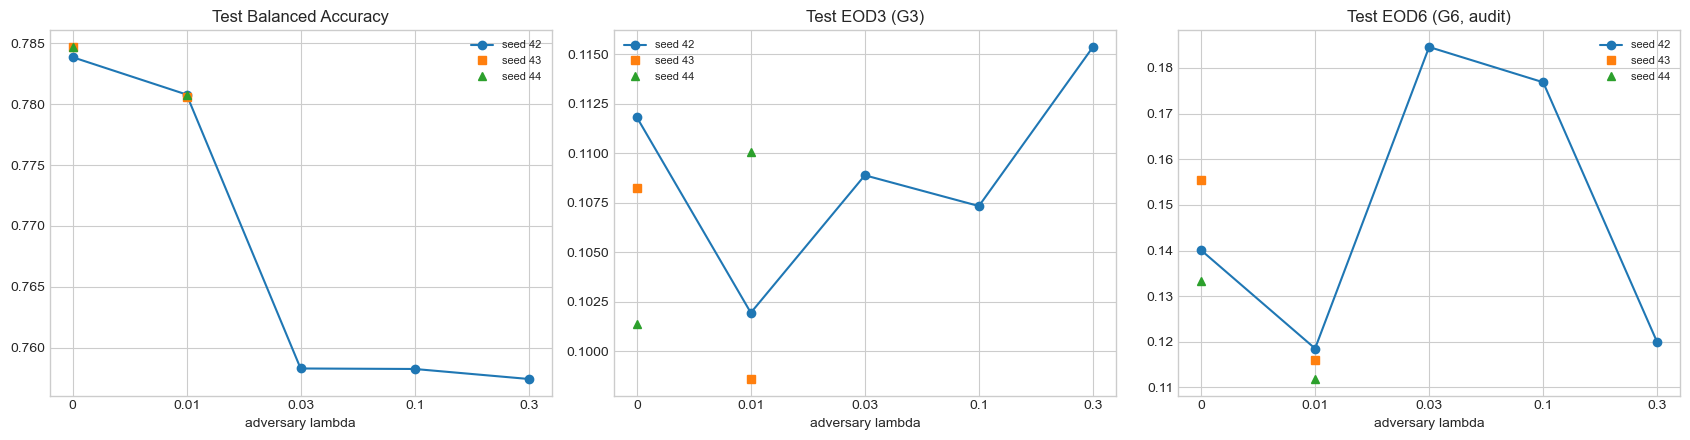

In [7]:
arm_metrics = read_table("arm_metrics.csv")
arm_metrics["role"] = arm_metrics["role"].map(ROLE_LABEL)
display(arm_metrics[["adversary_lambda", "seed", "role", "threshold", "test_rows", "balanced_accuracy", "eod3", "eod6_audit"]].sort_values(["adversary_lambda", "seed"]).round(6))
assert len(arm_metrics) == 9 and (arm_metrics["test_rows"] == 43996).all()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (column, title) in zip(axes, [("balanced_accuracy", "Test Balanced Accuracy"), ("eod3", "Test EOD3 (G3)"), ("eod6_audit", "Test EOD6 (G6, audit)")]):
    for seed, marker in zip(SEEDS, ["o", "s", "^"]):
        frame = arm_metrics[arm_metrics["seed"] == seed].sort_values("adversary_lambda")
        ax.plot([lam_label(v) for v in frame["adversary_lambda"]], frame[column], marker=marker, linestyle="-" if seed == 42 else "none", label=f"seed {seed}")
    ax.set_title(title)
    ax.set_xlabel("adversary lambda")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Per-group TPR, FPR and counts (Test)

These are the stored Test group metrics on `derived_race` for the fixed G3 and G6 rosters. TPR uses actual Approved applications as its denominator and FPR uses actual Denied applications. `Joint` is an application-level category, not an applicant race.

### Roster G3

fpr_approved                                                                 tpr_approved                                                                
adversary_lambda                  0.00                    0.01                    0.03    0.10    0.30         0.00                    0.01                    0.03    0.10    0.30
seed                                42      43      44      42      43      44      42      42      42           42      43      44      42      43      44      42      42      42
group                                                                                                                                                                              
White                           0.2876  0.2854  0.3002  0.3027  0.2995  0.2890  0.3672  0.3699  0.3413       0.8408  0.8393  0.8587  0.8496  0.8480  0.8360  0.8751  0.8733  0.8356
Black or African American       0.2715  0.2678  0.2898  0.2839  0.2935  0.2729  0.3507  0.3426  0.3155       0.8251  0.8270  0.8409  0.8390  0.8423  0.8266  0.8423  0.8409  0.8266
Asian                           0.3264  0.3243  0.3358  0.3389  0.3368  0.3326  0.3763  0.3628  0.3628       0.9370  0.9353  0.9423  0.9409  0.9409  0.9366  0.9512  0.9482  0.9419

### Roster G6

fpr_approved                                                                 tpr_approved                                                                
adversary_lambda                         0.00                    0.01                    0.03    0.10    0.30         0.00                    0.01                    0.03    0.10    0.30
seed                                       42      43      44      42      43      44      42      42      42           42      43      44      42      43      44      42      42      42
group                                                                                                                                                                                     
White                                  0.2876  0.2854  0.3002  0.3027  0.2995  0.2890  0.3672  0.3699  0.3413       0.8408  0.8393  0.8587  0.8496  0.8480  0.8360  0.8751  0.8733  0.8356
Black or African American              0.2715  0.2678  0.2898  0.2839  0.2935  0.2729  0.3507  0.3426  0.3155       0.8251  0.8270  0.8409  0.8390  0.8423  0.8266  0.8423  0.8409  0.8266
Asian                                  0.3264  0.3243  0.3358  0.3389  0.3368  0.3326  0.3763  0.3628  0.3628       0.9370  0.9353  0.9423  0.9409  0.9409  0.9366  0.9512  0.9482  0.9419
American Indian or Alaska Native       0.1948  0.1688  0.2208  0.2208  0.2208  0.2208  0.2857  0.2857  0.2727       0.8304  0.8571  0.8571  0.8393  0.8661  0.8482  0.8929  0.9107  0.8929
2 or more minority races               0.1864  0.2203  0.2203  0.2203  0.2373  0.2373  0.2712  0.2881  0.2542       0.8868  0.9057  0.9057  0.8868  0.9245  0.8868  0.9057  0.9057  0.8868
Joint                                  0.3265  0.2993  0.3537  0.3197  0.3265  0.3197  0.4558  0.4626  0.3741       0.9110  0.9045  0.9142  0.9094  0.9078  0.8851  0.9126  0.9045  0.9061

### Group counts (identical across arms for rows and actual labels)

,adversary_lambda,seed,group,row_count,actual_approved_count,actual_denied_count,predicted_approved_count,predicted_denied_count
0,0.00,42,2 or more minority races,112,53,59,58,54
1,0.00,42,American Indian or Alaska Native,189,112,77,108,81
2,0.00,42,Asian,3976,3014,962,3138,838
3,0.00,42,Black or African American,3456,2093,1363,2097,1359
4,0.00,42,Joint,765,618,147,611,154
5,0.00,42,White,27791,21421,6370,19843,7948
6,0.00,43,2 or more minority races,112,53,59,61,51
7,0.00,43,American Indian or Alaska Native,189,112,77,109,80
8,0.00,43,Asian,3976,3014,962,3131,845
9,0.00,43,Black or African American,3456,2093,1363,2096,1360


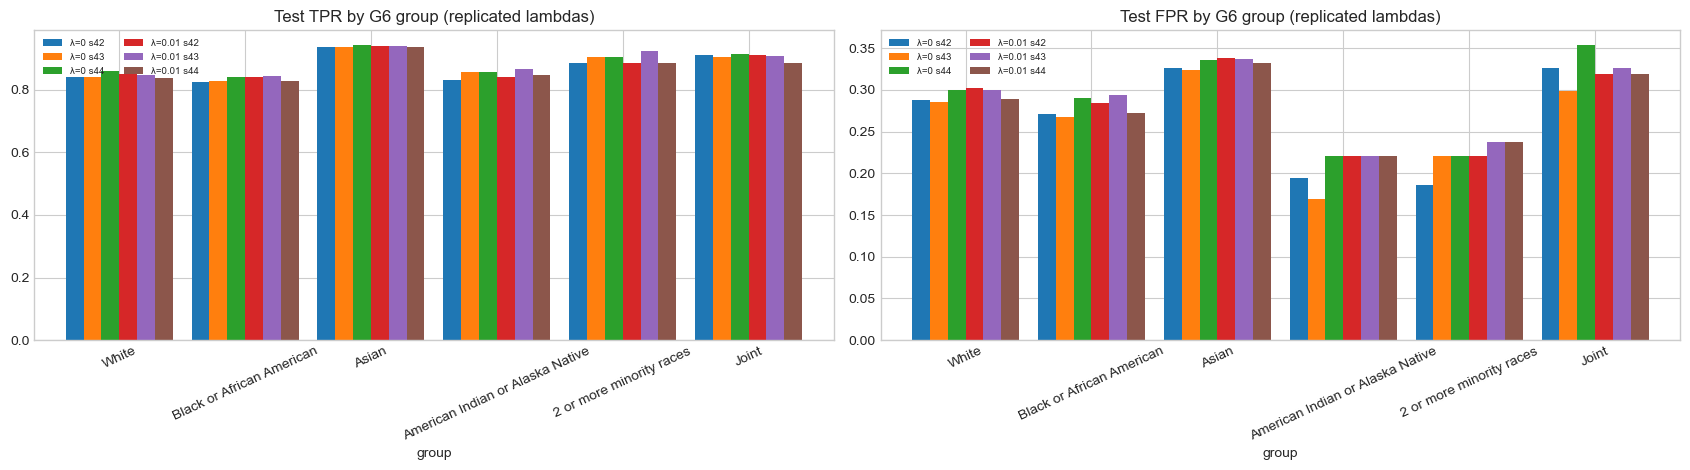

In [8]:
groups = read_table("group_metrics.csv")
assert len(groups) == 9 * (len(G3) + len(G6)) and groups["tpr_valid"].all() and groups["fpr_valid"].all()
for roster, members in (("g3", G3), ("g6", G6)):
    table = groups[groups["roster"] == roster]
    display(Markdown(f"### Roster {roster.upper()}"))
    display(table.pivot_table(index="group", columns=["adversary_lambda", "seed"], values=["tpr_approved", "fpr_approved"], aggfunc="first").reindex(members).round(4))
display(Markdown("### Group counts (identical across arms for rows and actual labels)"))
display(groups[groups["roster"] == "g6"][["adversary_lambda", "seed", "group", "row_count", "actual_approved_count", "actual_denied_count", "predicted_approved_count", "predicted_denied_count"]].sort_values(["adversary_lambda", "seed", "group"]).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), sharey=False)
replicated = groups[(groups["roster"] == "g6") & groups["adversary_lambda"].isin(REPLICATED_LAMBDAS)]
for ax, metric in zip(axes, ["tpr_approved", "fpr_approved"]):
    pivot = replicated.pivot_table(index="group", columns=["adversary_lambda", "seed"], values=metric, aggfunc="first").reindex(G6)
    pivot.columns = [f"λ={lam_label(lam)} s{seed}" for lam, seed in pivot.columns]
    pivot.plot.bar(ax=ax, rot=25, width=0.85)
    ax.set_title(f"Test {metric.split('_')[0].upper()} by G6 group (replicated lambdas)")
    ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## 7. Matched deltas and paired bootstrap intervals (Test)

Each delta is `comparator - control` for the same seed, where the control is lambda 0. The four seed-42 comparisons and one each at seeds 43 and 44 make six. Every comparison uses the locked 1,000 Test bootstrap rows, shared by both arms in each replicate. Intervals are two-sided 95% percentile intervals with `linear` quantiles, as stored in `bootstrap_summary.csv`. These intervals describe within-seed resampling uncertainty only. They are not pooled with the across-seed summaries.

,seed,comparator_lambda,control_lambda,delta_balanced_accuracy,delta_eod3,delta_eod6
0,42,0.01,0,-0.003071,-0.009874,-0.021552
1,42,0.03,0,-0.025583,-0.002933,0.044506
2,42,0.10,0,-0.025623,-0.004486,0.036781
3,42,0.30,0,-0.026446,0.003543,-0.020178
4,43,0.01,0,-0.004072,-0.009649,-0.039474
5,44,0.01,0,-0.003950,0.008693,-0.021541


,comparison,quantity,point_estimate,lower,upper,confidence_level,quantile_method,valid_replicates,invalid_replicates
0,s42 λ=0.01 vs 0,delta_balanced_accuracy,-0.003071,-0.005185,-0.001015,0.95,linear,1000,0
1,s42 λ=0.01 vs 0,delta_eod3,-0.009874,-0.021516,0.001939,0.95,linear,1000,0
2,s42 λ=0.01 vs 0,delta_eod6,-0.021552,-0.081185,0.030540,0.95,linear,1000,0
3,s42 λ=0.03 vs 0,delta_balanced_accuracy,-0.025583,-0.029054,-0.022102,0.95,linear,1000,0
4,s42 λ=0.03 vs 0,delta_eod3,-0.002933,-0.018999,0.014193,0.95,linear,1000,0
5,s42 λ=0.03 vs 0,delta_eod6,0.044506,-0.062273,0.122745,0.95,linear,1000,0
6,s42 λ=0.1 vs 0,delta_balanced_accuracy,-0.025623,-0.029127,-0.022011,0.95,linear,1000,0
7,s42 λ=0.1 vs 0,delta_eod3,-0.004486,-0.021010,0.013148,0.95,linear,1000,0
8,s42 λ=0.1 vs 0,delta_eod6,0.036781,-0.069993,0.121024,0.95,linear,1000,0
9,s42 λ=0.3 vs 0,delta_balanced_accuracy,-0.026446,-0.029714,-0.022930,0.95,linear,1000,0


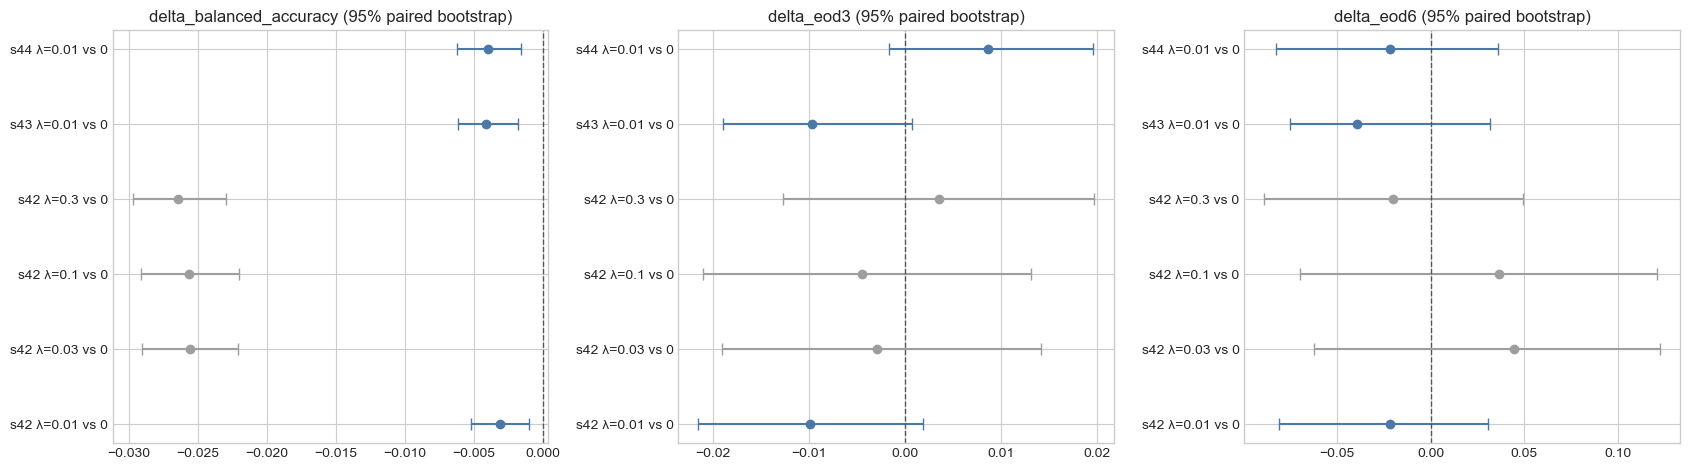

In [9]:
deltas = read_table("matched_deltas.csv")
summary = read_table("bootstrap_summary.csv")
point = deltas.melt(id_vars=["seed", "comparator_lambda", "control_lambda"], var_name="quantity", value_name="point_estimate")
intervals = summary.merge(point, on=["seed", "comparator_lambda", "control_lambda", "quantity"], how="left", validate="one_to_one")
assert len(deltas) == 6 and len(intervals) == 18 and intervals["point_estimate"].notna().all()
intervals["comparison"] = "s" + intervals["seed"].astype(str) + " λ=" + intervals["comparator_lambda"].map(lam_label) + " vs 0"
display(deltas.round(6))
display(intervals[["comparison", "quantity", "point_estimate", "lower", "upper", "confidence_level", "quantile_method", "valid_replicates", "invalid_replicates"]].round(6))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, quantity in zip(axes, ["delta_balanced_accuracy", "delta_eod3", "delta_eod6"]):
    subset = intervals[intervals["quantity"] == quantity].reset_index(drop=True)
    y = np.arange(len(subset))
    for position, row in zip(y, subset.itertuples()):
        color = "#4C78A8" if row.comparator_lambda == 0.01 else "#9E9E9E"
        ax.errorbar(row.point_estimate, position, xerr=[[row.point_estimate - row.lower], [row.upper - row.point_estimate]], fmt="o", color=color, capsize=4)
    ax.axvline(0.0, color="#555555", linestyle="--", linewidth=1)
    ax.set_yticks(y, subset["comparison"])
    ax.set_title(f"{quantity} (95% paired bootstrap)")
plt.tight_layout()
plt.show()

### Bootstrap replicate evidence

All 6,000 stored replicate rows are summarised here. The table checks that each comparison has replicate IDs 0-999 and that the valid counts per quantity equal those in `bootstrap_summary.csv`. The histograms show the stored replicate deltas.

rows  unique_ids  min_id  max_id  ba_valid  eod3_valid  eod6_valid
seed comparator_lambda                                                                    
42   0.01               1000        1000       0     999      1000        1000        1000
     0.03               1000        1000       0     999      1000        1000        1000
     0.10               1000        1000       0     999      1000        1000        1000
     0.30               1000        1000       0     999      1000        1000        1000
43   0.01               1000        1000       0     999      1000        1000        1000
44   0.01               1000        1000       0     999      1000        1000        1000

Replicate validity counts equal bootstrap_summary.csv for all 18 comparison-quantity pairs.


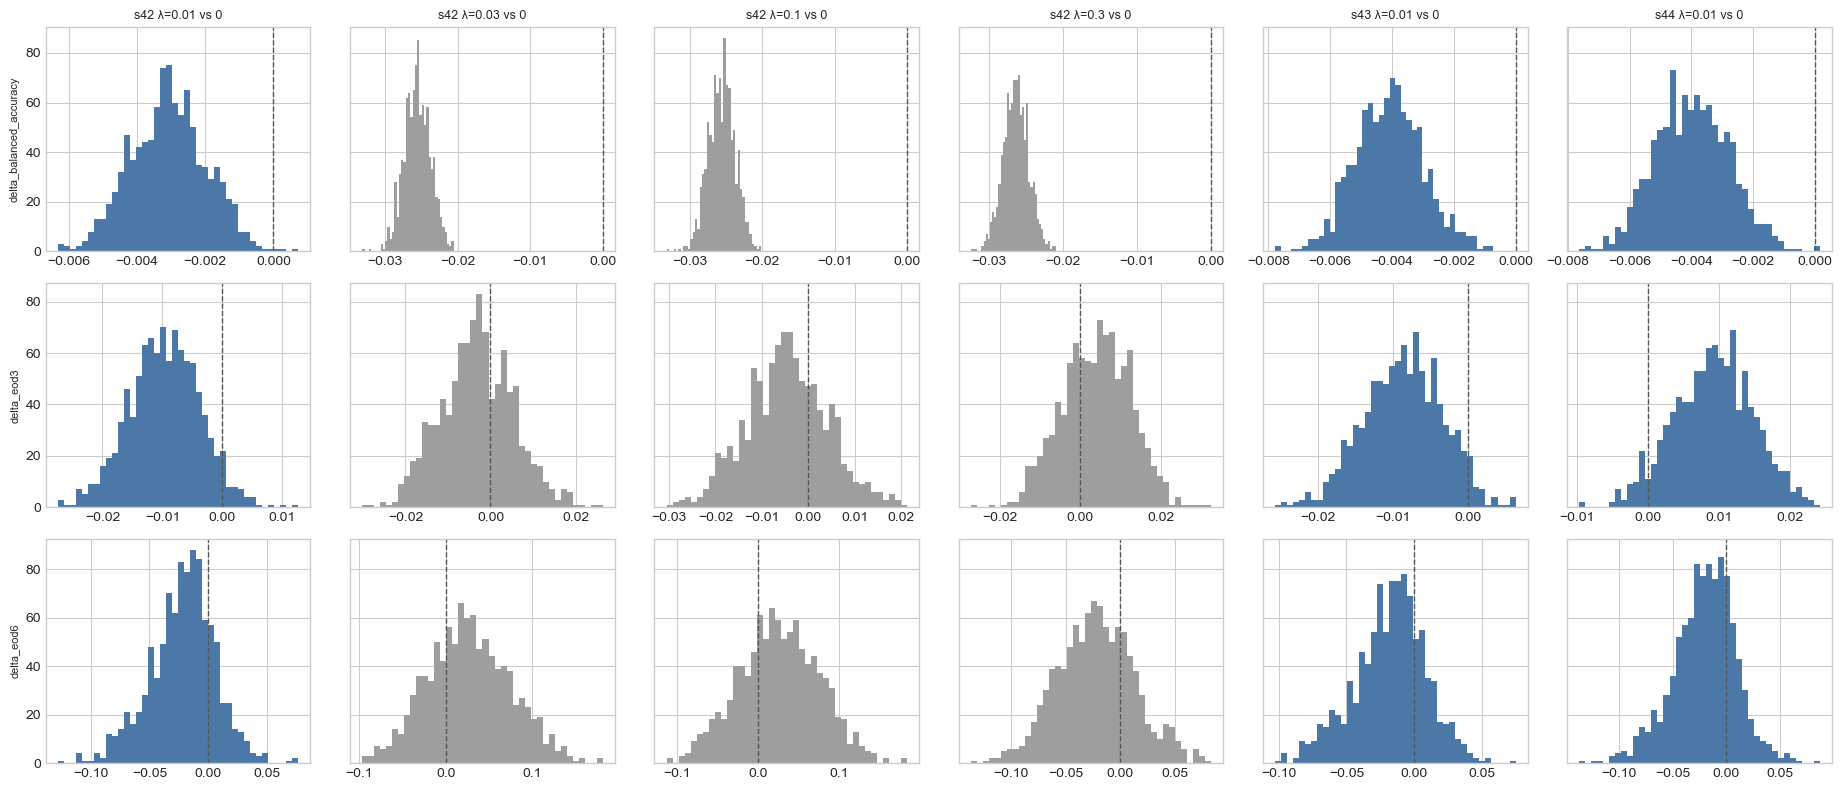

In [10]:
replicates = read_table("bootstrap_replicates.csv")
assert len(replicates) == 6000
coverage = replicates.groupby(["seed", "comparator_lambda"]).agg(rows=("replicate_id", "size"), unique_ids=("replicate_id", "nunique"), min_id=("replicate_id", "min"), max_id=("replicate_id", "max"), ba_valid=("balanced_accuracy_valid", "sum"), eod3_valid=("eod3_valid", "sum"), eod6_valid=("eod6_valid", "sum"))
display(coverage)
valid_column = {"delta_balanced_accuracy": "ba_valid", "delta_eod3": "eod3_valid", "delta_eod6": "eod6_valid"}
for row in summary.itertuples():
    assert coverage.loc[(row.seed, row.comparator_lambda), valid_column[row.quantity]] == row.valid_replicates, "Replicate validity differs from bootstrap_summary.csv."
print("Replicate validity counts equal bootstrap_summary.csv for all 18 comparison-quantity pairs.")

comparisons = list(replicates.groupby(["seed", "comparator_lambda"]).groups)
fig, axes = plt.subplots(3, len(comparisons), figsize=(3.1 * len(comparisons), 8), sharey="row")
for col, (seed, lam) in enumerate(comparisons):
    frame = replicates[(replicates["seed"] == seed) & (replicates["comparator_lambda"] == lam)]
    for row, quantity in enumerate(["delta_balanced_accuracy", "delta_eod3", "delta_eod6"]):
        axes[row, col].hist(frame[quantity].dropna(), bins=40, color="#4C78A8" if lam == 0.01 else "#9E9E9E")
        axes[row, col].axvline(0.0, color="#555555", linestyle="--", linewidth=1)
        if row == 0:
            axes[row, col].set_title(f"s{seed} λ={lam_label(lam)} vs 0", fontsize=9)
        if col == 0:
            axes[row, col].set_ylabel(quantity, fontsize=8)
plt.tight_layout()
plt.show()

## 8. Decision changes (Test)

These are the stored counts and rates of changed hard decisions between each comparator and its same-seed control, each at its own locked threshold. They are given overall and by group.

In [11]:
changes = read_table("decision_changes.csv")
assert len(changes) == 6 * (1 + len(G3) + len(G6))
display(changes.round(6))
overall = changes[changes["roster"] == "overall"]
display(Markdown("**Overall decision changes**"))
display(overall[["seed", "comparator_lambda", "row_count", "changed_count", "denied_to_approved_count", "approved_to_denied_count", "change_rate"]].round(6))

,seed,comparator_lambda,control_lambda,roster,group,row_count,unchanged_count,changed_count,denied_to_approved_count,approved_to_denied_count,change_rate
0,42,0.01,0,overall,__all__,43996,42110,1886,1157,729,0.042868
1,42,0.01,0,g3,White,27791,26496,1295,790,505,0.046598
2,42,0.01,0,g3,Black or African American,3456,3262,194,120,74,0.056134
3,42,0.01,0,g3,Asian,3976,3882,94,59,35,0.023642
4,42,0.01,0,g6,White,27791,26496,1295,790,505,0.046598
5,42,0.01,0,g6,Black or African American,3456,3262,194,120,74,0.056134
6,42,0.01,0,g6,Asian,3976,3882,94,59,35,0.023642
7,42,0.01,0,g6,American Indian or Alaska Native,189,184,5,4,1,0.026455
8,42,0.01,0,g6,2 or more minority races,112,104,8,5,3,0.071429
9,42,0.01,0,g6,Joint,765,743,22,10,12,0.028758


**Overall decision changes**

,seed,comparator_lambda,row_count,changed_count,denied_to_approved_count,approved_to_denied_count,change_rate
0,42,0.01,43996,1886,1157,729,0.042868
10,42,0.03,43996,4692,3108,1584,0.106646
20,42,0.10,43996,4814,3148,1666,0.109419
30,42,0.30,43996,4667,2595,2072,0.106078
40,43,0.01,43996,1791,1118,673,0.040708
50,44,0.01,43996,2033,637,1396,0.046209


## 9. Seed variability (Test, replicated lambdas)

These are the stored across-seed summaries over seeds 42, 43 and 44: mean, sample SD (ddof=1), min, max and range. They cover the per-arm metrics for lambdas 0 and 0.01 and the matched lambda-0.01 deltas. Screening lambdas have one seed and get no across-seed summary. Across-seed variation and within-seed bootstrap intervals are distinct uncertainty views and are not pooled.

,scope,adversary_lambda,comparator_lambda,control_lambda,quantity,seed_count,mean,standard_deviation,ddof,min,max,range
0,per_arm,0.00,NaN,NaN,balanced_accuracy,3,0.784415,0.000478,1,0.783864,0.784698,0.000834
1,per_arm,0.00,NaN,NaN,eod3,3,0.107153,0.005316,1,0.101371,0.111829,0.010458
2,per_arm,0.00,NaN,NaN,eod6_audit,3,0.142995,0.011328,1,0.133403,0.155493,0.022091
3,per_arm,0.01,NaN,NaN,balanced_accuracy,3,0.780718,0.000093,1,0.780613,0.780792,0.000180
4,per_arm,0.01,NaN,NaN,eod3,3,0.103543,0.005890,1,0.098611,0.110064,0.011454
5,per_arm,0.01,NaN,NaN,eod6_audit,3,0.115473,0.003372,1,0.111861,0.118538,0.006677
6,matched_delta,NaN,0.01,0.0,delta_balanced_accuracy,3,-0.003698,0.000546,1,-0.004072,-0.003071,0.001000
7,matched_delta,NaN,0.01,0.0,delta_eod3,3,-0.003610,0.010655,1,-0.009874,0.008693,0.018567
8,matched_delta,NaN,0.01,0.0,delta_eod6,3,-0.027522,0.010350,1,-0.039474,-0.021541,0.017933


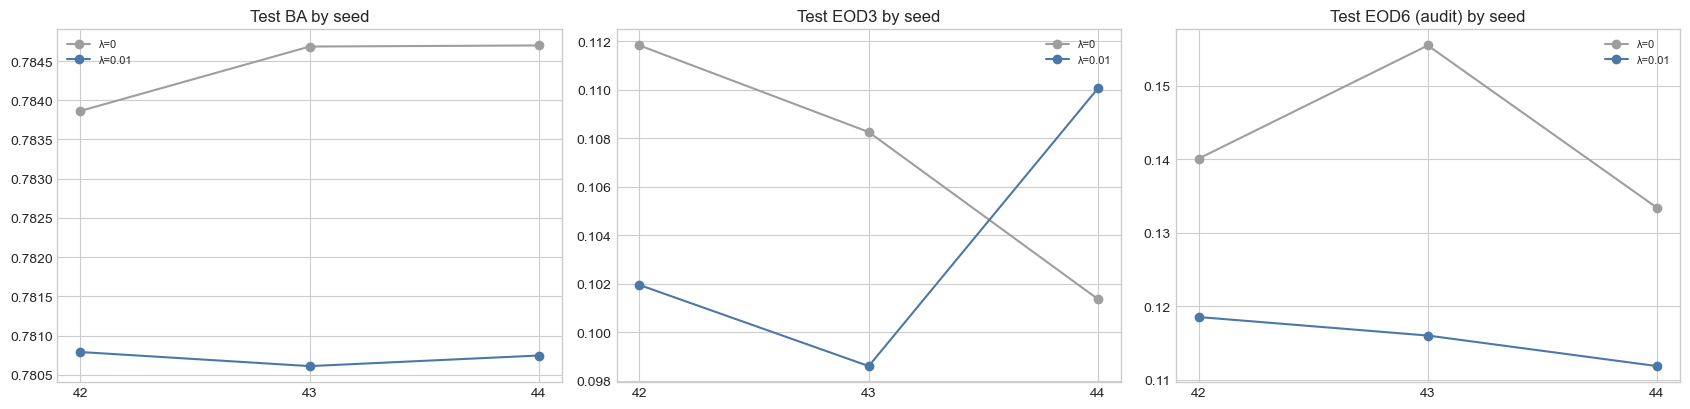

In [12]:
across = read_table("across_seed_summary.csv")
assert len(across) == 9 and (across["seed_count"] == 3).all()
display(across.round(6))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (column, title) in zip(axes, [("balanced_accuracy", "Test BA by seed"), ("eod3", "Test EOD3 by seed"), ("eod6_audit", "Test EOD6 (audit) by seed")]):
    for lam, color in zip(REPLICATED_LAMBDAS, ["#9E9E9E", "#4C78A8"]):
        frame = arm_metrics[arm_metrics["adversary_lambda"] == lam].sort_values("seed")
        ax.plot(frame["seed"].astype(str), frame[column], marker="o", color=color, label=f"λ={lam_label(lam)}")
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Validation-to-Test generalization gaps

Each gap is `Test value - Validation value` for the same arm and the same locked threshold, as stored in `generalization_gaps.csv`. The Validation values stored there are checked against the Gate C unit rows above.

In [13]:
gaps = read_table("generalization_gaps.csv")
assert len(gaps) == 27 and gaps["test_minus_validation"].notna().all()
display(gaps.pivot_table(index=["adversary_lambda", "seed"], columns="quantity", values=["validation_value", "test_value", "test_minus_validation"], aggfunc="first").round(6))

gate_c_lookup = validation_units.set_index(["adversary_lambda", "model_seed"])
for row in gaps.itertuples():
    stored = gate_c_lookup.loc[(row.adversary_lambda, row.seed), {"balanced_accuracy": "balanced_accuracy", "eod3": "eod3", "eod6": "eod6_audit_only"}[row.quantity]]
    assert abs(stored - row.validation_value) <= ATOL_POINT, f"Validation value differs from Gate C for {row.adversary_lambda}/{row.seed}/{row.quantity}."
gap_lookup = gaps.set_index(["adversary_lambda", "seed", "quantity"])["test_value"]
for row in arm_metrics.itertuples():
    for quantity, column in (("balanced_accuracy", "balanced_accuracy"), ("eod3", "eod3"), ("eod6", "eod6_audit")):
        assert abs(gap_lookup.loc[(row.adversary_lambda, row.seed, quantity)] - getattr(row, column)) <= ATOL_POINT, "Gap Test value differs from arm_metrics.csv."
print("Gap Validation values equal Gate C unit rows and gap Test values equal arm_metrics.csv (atol 1e-12).")

test_minus_validation                            test_value                      validation_value                    
quantity                  balanced_accuracy      eod3      eod6 balanced_accuracy      eod3      eod6 balanced_accuracy      eod3      eod6
adversary_lambda seed                                                                                                                      
0.00             42               -0.003875  0.009654 -0.057624          0.783864  0.111829  0.140090          0.787739  0.102175  0.197714
                 43               -0.002161  0.007750 -0.055479          0.784684  0.108259  0.155493          0.786845  0.100510  0.210972
                 44               -0.003432  0.005155 -0.067231          0.784698  0.101371  0.133403          0.788131  0.096216  0.200634
0.01             42               -0.001652  0.004166 -0.103040          0.780792  0.101955  0.118538          0.782444  0.097789  0.221579
                 43               -0.002782  0.000066 -0.098162          0.780613  0.098611  0.116019          0.783395  0.098545  0.214181
                 44               -0.001096 -0.001525 -0.103506          0.780748  0.110064  0.111861          0.781844  0.111589  0.215367
0.03             42               -0.001651  0.007135 -0.056524          0.758281  0.108896  0.184596          0.759932  0.101761  0.241119
0.10             42               -0.000673  0.010276 -0.050640          0.758241  0.107343  0.176871          0.758913  0.097067  0.227511
0.30             42               -0.002139  0.012895 -0.081663          0.757418  0.115373  0.119912          0.759557  0.102478  0.201576

Gap Validation values equal Gate C unit rows and gap Test values equal arm_metrics.csv (atol 1e-12).


## 11. Screening arms (lambda 0.03, 0.1, 0.3; seed 42 only)

The screening arms were requested explicitly for complete numerical reporting. Each has one seed, so no across-seed summary exists. Each is compared only with the seed-42 lambda-0 control. The rows below gather their stored Validation, Test, matched-delta, interval and gap values in one place.

In [14]:
screen_validation = validation_units[validation_units["adversary_lambda"].isin(SCREENING_LAMBDAS)][["adversary_lambda", "model_seed", "threshold", "balanced_accuracy", "eod3", "eod6_audit_only", "matched_delta_ba"]]
screen_test = arm_metrics[arm_metrics["adversary_lambda"].isin(SCREENING_LAMBDAS)][["adversary_lambda", "seed", "threshold", "balanced_accuracy", "eod3", "eod6_audit"]]
screen_intervals = intervals[intervals["comparator_lambda"].isin(SCREENING_LAMBDAS)][["comparison", "quantity", "point_estimate", "lower", "upper", "valid_replicates"]]
display(Markdown("**Validation (Gate C, seed 42)**"))
display(screen_validation.round(6))
display(Markdown("**Test (seed 42)**"))
display(screen_test.round(6))
display(Markdown("**Matched deltas vs seed-42 control with 95% paired bootstrap intervals**"))
display(screen_intervals.round(6))
assert across[across["adversary_lambda"].isin(SCREENING_LAMBDAS) | across["comparator_lambda"].isin(SCREENING_LAMBDAS)].empty, "Screening lambdas must have no across-seed summary."

**Validation (Gate C, seed 42)**

,adversary_lambda,model_seed,threshold,balanced_accuracy,eod3,eod6_audit_only,matched_delta_ba
6,0.03,42,0.741,0.759932,0.101761,0.241119,-0.027806
7,0.10,42,0.738,0.758913,0.097067,0.227511,-0.028825
8,0.30,42,0.836,0.759557,0.102478,0.201576,-0.028182


**Test (seed 42)**

,adversary_lambda,seed,threshold,balanced_accuracy,eod3,eod6_audit
6,0.03,42,0.741,0.758281,0.108896,0.184596
7,0.10,42,0.738,0.758241,0.107343,0.176871
8,0.30,42,0.836,0.757418,0.115373,0.119912


**Matched deltas vs seed-42 control with 95% paired bootstrap intervals**

,comparison,quantity,point_estimate,lower,upper,valid_replicates
3,s42 λ=0.03 vs 0,delta_balanced_accuracy,-0.025583,-0.029054,-0.022102,1000
4,s42 λ=0.03 vs 0,delta_eod3,-0.002933,-0.018999,0.014193,1000
5,s42 λ=0.03 vs 0,delta_eod6,0.044506,-0.062273,0.122745,1000
6,s42 λ=0.1 vs 0,delta_balanced_accuracy,-0.025623,-0.029127,-0.022011,1000
7,s42 λ=0.1 vs 0,delta_eod3,-0.004486,-0.021010,0.013148,1000
8,s42 λ=0.1 vs 0,delta_eod6,0.036781,-0.069993,0.121024,1000
9,s42 λ=0.3 vs 0,delta_balanced_accuracy,-0.026446,-0.029714,-0.022930,1000
10,s42 λ=0.3 vs 0,delta_eod3,0.003543,-0.012715,0.019751,1000
11,s42 λ=0.3 vs 0,delta_eod6,-0.020178,-0.089106,0.049535,1000


## 12. Key values for reconciliation

The values below are copied without transformation from the stored artifacts, so they can be compared directly with the files.

In [15]:
key_values = {
    "gate_c": {"selected_lambda": selection["selected_lambda"], "candidates": selection["candidates"]},
    "test_execution_status": execution_status,
    "package_validation": {"receipt_status": package_receipt["status"], "inference_performed": package_report["inference_performed"], "recomputed_from_saved_predictions": package_report["recomputed_from_saved_predictions"]},
    "test_arms": {f"lambda={lam_label(row.adversary_lambda)}/seed={row.seed}": {"threshold": row.threshold, "balanced_accuracy": row.balanced_accuracy, "eod3": row.eod3, "eod6_audit": row.eod6_audit} for row in arm_metrics.itertuples()},
    "matched_deltas_with_ci": {f"{row.comparison}/{row.quantity}": [row.point_estimate, row.lower, row.upper, int(row.valid_replicates)] for row in intervals.itertuples()},
}
print(json.dumps(key_values, indent=1))

{
 "gate_c": {
  "selected_lambda": 0.0,
  "candidates": [
   {
    "adversary_lambda": 0.0,
    "eligible": true,
    "invalid_reason": null,
    "mean_eod3": 0.09963349695844419,
    "mean_matched_delta_ba": 0.0
   },
   {
    "adversary_lambda": 0.01,
    "eligible": true,
    "invalid_reason": null,
    "mean_eod3": 0.10264080067149206,
    "mean_matched_delta_ba": -0.005010582994129782
   }
  ]
 },
 "test_execution_status": {
  "cv_fit_count": 0,
  "execution_status": "completed",
  "fit_count": 0,
  "inference_count": 9,
  "reason_codes": [
   "none"
  ],
  "refit_count": 0,
  "test_rows": 43996
 },
 "package_validation": {
  "receipt_status": "PASS",
  "inference_performed": false,
  "recomputed_from_saved_predictions": true
 },
 "test_arms": {
  "lambda=0/seed=42": {
   "threshold": 0.763,
   "balanced_accuracy": 0.7838638003677878,
   "eod3": 0.11182945902082675,
   "eod6_audit": 0.14008993427879624
  },
  "lambda=0/seed=43": {
   "threshold": 0.766,
   "balanced_accuracy": 0.

## 13. Interpretation boundary

- Execution success, receipt `PASS` and package-validation `PASS` describe integrity and reproducibility only. They are not research results.
- No research pass/fail, mitigation-effectiveness, support or recommendation label is computed or implied by this notebook or by the packages it reads.
- Validation thresholds and the Gate C lambda selection share the complete Validation partition, so Validation values are optimistic. Test was opened once for a fixed, user-selected nine-arm roster. No lambda, threshold or seed is selected on Test.
- Only three seeds exist for the replicated lambdas, and the screening lambdas have one seed. Within-seed bootstrap intervals and across-seed summaries are separate uncertainty views.
- The stored `training-unstable beyond selected epoch` limitation applies to the lambda > 0 units (see the Gate C training-stability labels above).
- These outputs describe approval-prediction behaviour for the documented HMDA cohort. They cannot establish legal compliance, discrimination, causal effects, creditworthiness or default risk.

## 14. Research interpretation (user-owned)

*Reserved for the user's interpretation and conclusions. Not written by code.*